In [ ]:
import pysam
import sgkit as sg
from sgkit.io.vcf import vcf_to_zarr

vcf_file = "./filtered_tree_genotypes.vcf"
vcf_gz = vcf_file +".gz"

# Step 1: Compress the VCF using bgzip (if not already compressed)
pysam.tabix_compress(vcf_file, vcf_gz, force=True)

# Step 2: Index the bgzipped VCF file
pysam.tabix_index(vcf_gz, preset="vcf", force=True)

vcf_to_zarr(vcf_gz, "./trees_cleaned.zarr", ploidy=6)

In [7]:
import xarray as xr
import numpy as np
import pandas as pd

# Read a local Zarr store
ds = xr.open_zarr("./trees_cleaned.zarr")

sample_ids = ds['sample_id'].values

population_coordinates = {
    "YB_101": (-68.629385, 44.85768),
    "YB_102": (-70.668625, 43.441785),
    "YB_103": (-79.670559, 39.05127),
    "YB_104": (-78.773145, 41.597266),
    "YB_105": (-87.164049, 46.359099),
    "YB_106": (-88.977224, 45.753117),
    "YB_107": (-85.6758, 35.180891),
    "YB_109": (-85.092092, 35.326663),
    "YB_110": (-81.415259, 36.741569),
    "YB_1101": (-73.09424, 45.32164),
    "YB_1102": (-89.403444, 48.273194),
    "YB_1103": (-84.567945, 47.341619),
    "YB_1104": (-83.415001, 46.266671),
    "YB_111": (-79.230005, 37.753601),
    "YB_112": (-71.295105, 44.053137),
    "YB_113": (-90.751057, 48.393144),
    "YB_114": (-93.470861, 47.531132),
    "YB_115": (-93.675717, 47.115476),
    "YB_116": (-90.574611, 43.663951),
    "YB_118": (-79.21455, 45.584417),
    "YB_119": (-77.489004, 44.198676),
    "YB_120": (-76.774508, 42.488922),
    "YB_121": (-73.254641, 42.728327),
    "YB_122": (-82.733587, 35.433109),
    "YB_123": (-76.287615, 41.322044),
    "YB_2004": (-64.88, 45.8),
    "YB_CF": (-79.70048, 44.56741),
}

sample_coordinates = {
    str(sample): population_coordinates[str(sample).split("-", 1)[0]]
    for sample in sample_ids
}

Number of nodes: 1863
Number of edges: 5350


<Figure size 5000x4000 with 0 Axes>

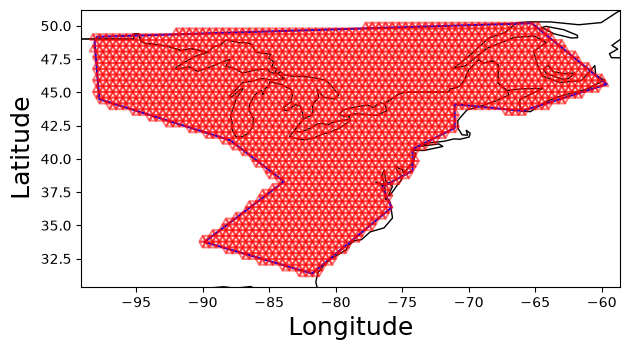

In [8]:
from dreems.utils.utility import create_grid
import networkx as nx

outer_coordinates = [
    (-98.120453, 48.825960),
    (-97.768890, 44.485845),
    (-87.925140, 41.398567),
    (-83.882171, 38.295453),
    (-89.858734, 33.748457),
    (-81.772796, 31.378400),
    (-75.796234, 36.338490),
    (-76.499359, 37.880401),
    (-74.214203, 39.118467),
    (-74.214203, 40.735934),
    (-71.050140, 42.315013),
    (-71.050140, 44.108412),
    (-65.952484, 43.601396),
    (-59.624359, 45.603583),
    (-65.249359, 50.195467),
    (-97.944671, 49.171934),
]

grid = create_grid(outer_coordinates, grid_size=0.5, pad=1.0)

nodes = np.array([list(coord) for coord in nx.get_node_attributes(grid, 'pos').values()])
edges = np.array(list(grid.edges))

In [9]:
from dreems.utils.utility import dreems_infer

surface = dreems_infer(ds, sample_coordinates, nodes, edges)

{"conditioner_failure_examples": [], "conditioner_failures": 0, "conditioner_observed_nodes_mean": 27.0, "conditioner_observed_pairs_mean": 351.0, "conditioner_seconds_total": 0.0907247792929411, "edge_conditioner": "linearized_resistance", "edge_conditioner_methods": ["all_pair_diagonal_adjoint"], "edge_dim_after": 253, "edge_dim_before": 251, "examples": 1, "stage": "append_edge_conditioner_features"}


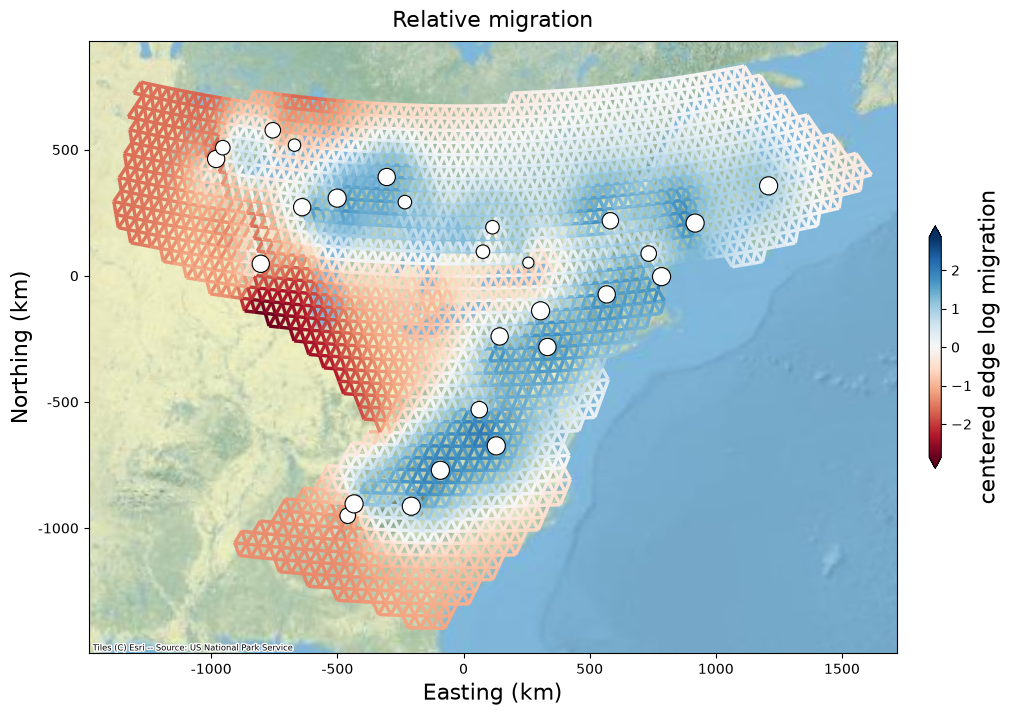

In [10]:
from dreems.utils.plotting import draw_projected_grid_map

draw_projected_grid_map(
    surface
)

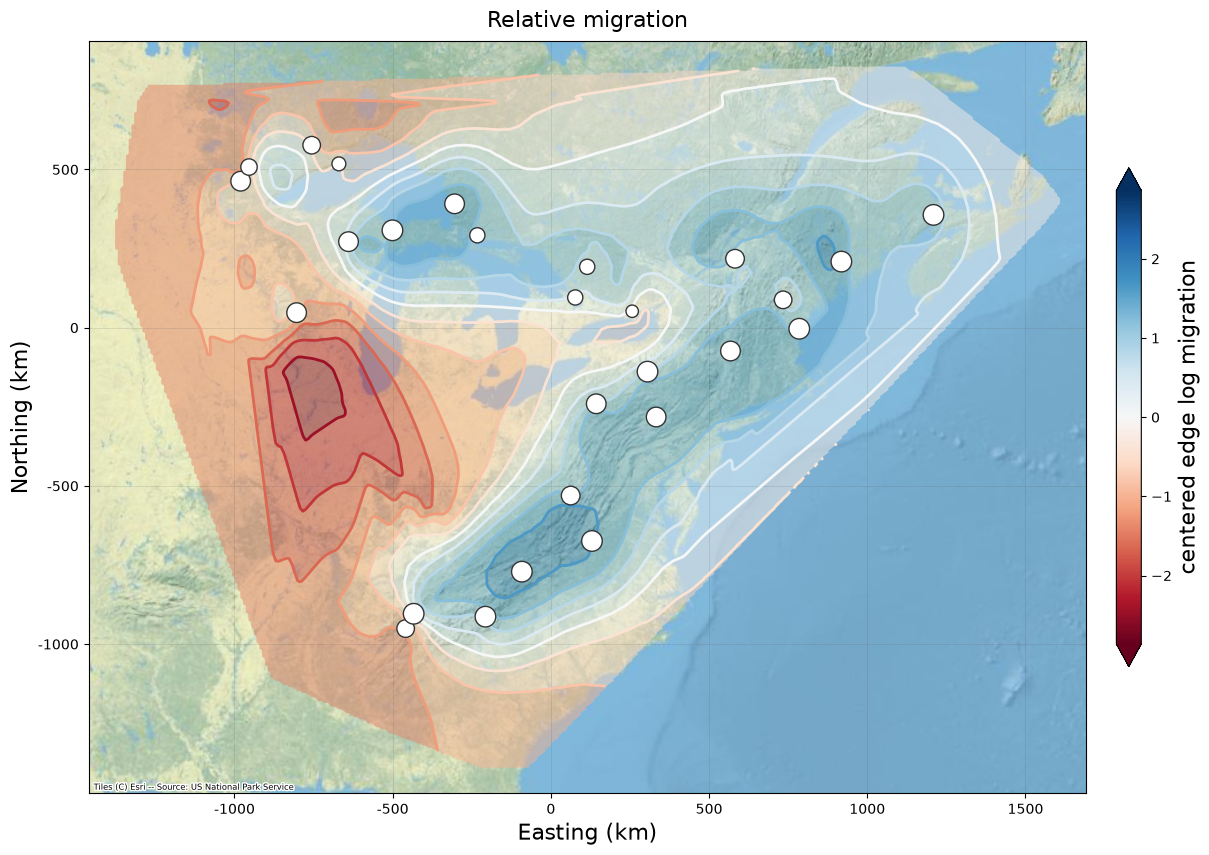

(<Figure size 1200x1000 with 2 Axes>,
 <Axes: title={'center': 'Relative migration'}, xlabel='Easting (km)', ylabel='Northing (km)'>)

In [12]:
from dreems.utils.plotting import draw_projected_contour_map

draw_projected_contour_map(
    surface,
    smoothing_km=5.0,
    contour_fill_alpha = 0.50,
    contour_line_alpha=1.0,
    contour_levels=15,
    map_margin_km=75.0,
    posterior=False,
    figure_path="yellow_birch.pdf"
)